# Автор решения: Иванова Виктория

# Шаг 0. Необходимые импорты

In [138]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

try:
    import duckdb
except ImportError as e:
    raise ImportError("Нужен пакет duckdb для SQL-блоков: pip install duckdb") from e

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

# Канонический путь: analytics_school/data рядом с ноутбуком
DATA = Path("data")
# if not DATA.exists():
#     # запасной вариант, если ядро запущено из корня репозитория
#     DATA = Path("hh-science/k.guliev/analytics_school/data")

assert DATA.exists(), f"Не найдена папка с данными: {DATA.resolve()}"

# Регистрируем CSV как таблицы, чтобы обращаться к ним из SQL
con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    # year/month/day должны остаться строками с ведущими нулями ('07'),
    # иначе фильтр вида day BETWEEN '01' AND '28' сравнит строки неправильно
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк  <- {filename}")
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")
employer_spend = register_csv("employer_spend", "employer_spend.csv")
experiment_clients = register_csv("experiment_clients", "experiment_clients.csv")
incident_events = register_csv("incident_events", "incident_events.csv")

def sql(query: str) -> pd.DataFrame:
    # Выполнить SQL-запрос (в стиле Trino) к синтетическим таблицам
    return con.execute(query).df()

print("\nГотово. Для запросов используйте функцию sql('''...''').")


impressions                    80,000 строк  <- impressions.csv
clicks                          3,837 строк  <- clicks.csv
responses                         421 строк  <- responses.csv
product_daily                     252 строк  <- product_daily.csv
employer_spend                  2,400 строк  <- employer_spend.csv
experiment_clients             12,573 строк  <- experiment_clients.csv
incident_events                25,500 строк  <- incident_events.csv

Готово. Для запросов используйте функцию sql('''...''').


In [139]:
from typing import Iterable, Optional, Sequence, Tuple


def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    # Доверительный интервал Уилсона для доли. Устойчивее нормального приближения
    # на малых выборках и у краёв (доля близка к 0 или 1).
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def proportion_table(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    success_col: str,
    n_col: str,
    rate_name: str = "rate",
) -> pd.DataFrame:
    # Считает долю по группам и добавляет доверительный интервал Уилсона.
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g


def period_flag(dates: pd.Series, cutoff: str, before="before", after="after") -> pd.Series:
    # Размечает даты на период до и после точки cutoff.
    d = pd.to_datetime(dates)
    return np.where(d < pd.Timestamp(cutoff), before, after)


def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)


def one_pager(
    decision: str,
    context: str,
    what_done: str,
    result: str,
    limits: str,
    action: str,
) -> str:
    # Собирает итоговую справку с выводом наверху.
    parts = [
        "=" * 60,
        "ИТОГОВАЯ СПРАВКА",
        "=" * 60,
        "",
        "Решение:",
        decision,
        "",
        "Контекст:",
        context,
        "",
        "Что сделали:",
        what_done,
        "",
        "Результат:",
        result,
        "",
        "Ограничения:",
        limits,
        "",
        "Рекомендованное действие:",
        action,
        "=" * 60,
    ]
    return "\n".join(parts)


print("Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager")


Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager


# Шаг 1. ТЗ и глубина

20 июля на Android кликабельность top_search резко выше обычной. 


| Поле ТЗ | Значение |
|---|---|
| Цель | Понять, что стоит за увеличением кликабельности 20 июля на Android: ошибки логирования или реальный эффект |
| Гипотеза | Увеличение кликабельности не связано с ошибками логирования, пользователи действительно кликали чаще |
| Метрика | Кликабельность; конверсия из клика в отклик; конверсия из показа в отклик|
| Период | 1–28 июля 2026; 20.07 сравниваем с остальными днями  |
| Сегменты | Платформа, продукт, сегмент работодателя |
| Критерий | Данные целостны, отклики выросли вместе с кликами (конверсия из клика в отклик на уровне фона), отклик/показ растёт, выброс одинаков по сегментам, другие платформы не затронуты |
| Решение | Отправить задачу мобильной разработке и аналитикам данных на логирование или сообщить продакт-менеджеру о наличии эффекта |

Глубина: разбор. Цена ошибки средняя (неверное решение о формате на Android или впустую потраченное время разработки), оба решения откатываются
без следа.

# Шаг 2. Качество данных

Проверяем три вещи: таблицы целы (2.1), воронка показ → клик → отклик связная (2.2) и 20.07 на Android не похож на ошибку логирования (2.3–2.4).

### 2.1. Базовые проверки таблиц
Смотрим размер, полные дубли, пропуски, дубли по первичному ключу и написание платформ, продуктов и сегментов.

In [140]:
display(summarize_dq(impressions, key_cols=["impression_id"]))
display(summarize_dq(clicks,      key_cols=["click_id"]))
display(summarize_dq(responses,   key_cols=["response_id"]))

# Категориальные поля: во всех таблицах должен быть один и тот же набор значений
for name, t in (("impressions", impressions), ("clicks", clicks), ("responses", responses)):
    print(f"{name:12s} platform={sorted(t['platform'].unique())}")
    print(f"{'':12s} product={sorted(t['product'].unique())} segment={sorted(t['segment'].unique())}")

,проверка,значение
0,строк всего,80000
1,полных дублей строк,0
2,пропуски: impression_id,0
3,пропуски: event_date,0
4,пропуски: platform,0
5,пропуски: segment,0
6,пропуски: product,0
7,пропуски: vacancy_id,0
8,пропуски: employer_id,0
9,пропуски: hhuid,0


,проверка,значение
0,строк всего,3837
1,полных дублей строк,0
2,пропуски: click_id,0
3,пропуски: impression_id,0
4,пропуски: event_date,0
5,пропуски: platform,0
6,пропуски: segment,0
7,пропуски: product,0
8,пропуски: vacancy_id,0
9,пропуски: employer_id,0


,проверка,значение
0,строк всего,421
1,полных дублей строк,0
2,пропуски: response_id,0
3,пропуски: click_id,0
4,пропуски: impression_id,0
5,пропуски: event_date,0
6,пропуски: platform,0
7,пропуски: segment,0
8,пропуски: product,0
9,пропуски: vacancy_id,0


impressions  platform=['ANDROID', 'DESKTOP_WEB', 'IOS', 'MOBILE_WEB']
             product=['top_boost', 'top_search'] segment=['Large', 'Premium', 'SMB']
clicks       platform=['ANDROID', 'DESKTOP_WEB', 'IOS', 'MOBILE_WEB']
             product=['top_boost', 'top_search'] segment=['Large', 'Premium', 'SMB']
responses    platform=['ANDROID', 'DESKTOP_WEB', 'IOS', 'MOBILE_WEB']
             product=['top_boost', 'top_search'] segment=['Large', 'Premium', 'SMB']


Дублей и пропусков нет, названия платформ, продуктов и сегментов во всех таблицах одинаковые.

### 2.2. Связность воронки
Если трекинг сломан, воронка обычно рвётся: появляются клики без показа, отклики без клика, несколько кликов на один показ.

In [141]:
# orphan_clicks - клики, для которых нет показа
# orphan_responses - отклики, для которых нет клика
# max_clicks_per_impr - максимум кликов на один показ
# attr_mismatch - клик и его показ расходятся по платформе, продукту или дате
sql('''
SELECT
    (
        SELECT COUNT(*)
        FROM clicks c
        LEFT JOIN impressions i ON i.impression_id = c.impression_id
        WHERE i.impression_id IS NULL
    ) AS orphan_clicks,

    (
        SELECT COUNT(*)
        FROM responses r
        LEFT JOIN clicks c ON c.click_id = r.click_id
        WHERE c.click_id IS NULL
    ) AS orphan_responses,

    (
        SELECT MAX(cnt)
        FROM (
            SELECT impression_id, COUNT(*) AS cnt
            FROM clicks
            GROUP BY impression_id
        ) t
    ) AS max_clicks_per_impr,

    (
        SELECT COUNT(*)
        FROM clicks c
        JOIN impressions i ON i.impression_id = c.impression_id
        WHERE c.platform <> i.platform
           OR c.product <> i.product
           OR c.event_date <> i.event_date
    ) AS attr_mismatch
''')

,orphan_clicks,orphan_responses,max_clicks_per_impr,attr_mismatch
0,0,0,1,0


Воронка связная: осиротевших кликов и откликов нет, на один показ приходится не больше одного клика, платформа, продукт и дата у клика и его показа совпадают.

### 2.3. Выброс 20.07
Смотрим распределение дневной кликабельности по платформам (top_search): где есть дни, сильно выбивающиеся из обычного.

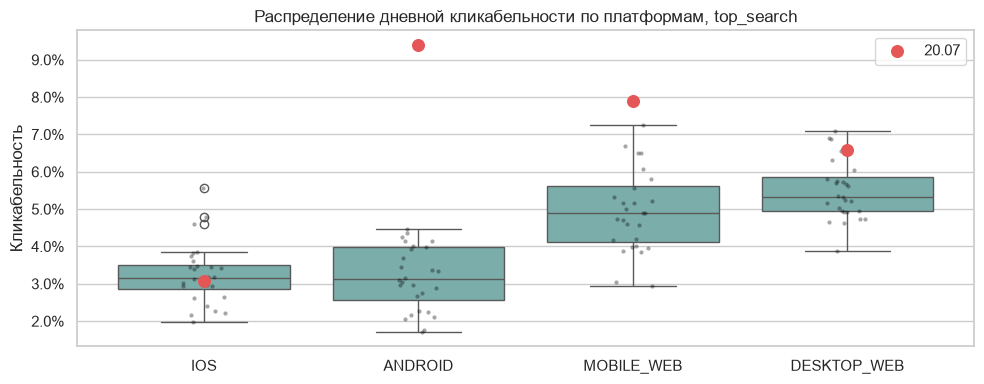

Дни Android с самой высокой кликабельностью (кандидаты на проблему трекинга):


,event_date,platform,impressions,clicks,ctr
1,2026-07-20,ANDROID,383,36.0,0.093995
69,2026-07-27,ANDROID,380,17.0,0.044737
27,2026-07-09,ANDROID,598,26.0,0.043478


In [142]:
daily = sql('''
SELECT
    i.event_date,
    i.platform,
    COUNT(*) AS impressions,
    SUM(CASE WHEN c.click_id IS NOT NULL THEN 1 ELSE 0 END) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.product = 'top_search'
  AND i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
GROUP BY 1, 2
''')
daily["ctr"] = daily["clicks"] / daily["impressions"]

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=daily, x="platform", y="ctr", ax=ax, color="#72B7B2")
is_0720 = daily["event_date"].astype(str).str[:10] == "2026-07-20"
sns.stripplot(data=daily[~is_0720], x="platform", y="ctr", ax=ax, color="black", size=3, alpha=0.35)
order = [t.get_text() for t in ax.get_xticklabels()]
d0720 = daily[is_0720]
ax.scatter([order.index(p) for p in d0720["platform"]], d0720["ctr"], color="#E45756", s=70, zorder=5, label="20.07")
ax.legend()
ax.set_title("Распределение дневной кликабельности по платформам, top_search")
ax.set_ylabel("Кликабельность")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
fig_dist = fig 
plt.tight_layout()
plt.show()

anomaly = daily[(daily["platform"] == "ANDROID")].sort_values("ctr", ascending=False).head(3)
print("Дни Android с самой высокой кликабельностью (кандидаты на проблему трекинга):")
display(anomaly)

### 2.4. Проверка на ошибки логирования
Типичная ошибка логирования — событие записано дважды. Ищем такие повторы и смотрим, что именно выросло 20.07 на Android: показы или клики.

In [143]:
print("Повторов кликов по пользователь - вакансия - день:", int(clicks.duplicated(["hhuid", "vacancy_id", "event_date"]).sum()))

andr = (impressions[impressions["platform"] == "ANDROID"].groupby("event_date").size().rename("показы").to_frame()
        .join(clicks[clicks["platform"] == "ANDROID"].groupby("event_date").size().rename("клики")))
andr["кликабельность"] = andr["клики"] / andr["показы"]
rest = andr.drop(index="2026-07-20")
display(pd.DataFrame({"20.07": andr.loc["2026-07-20"],
                      "остальные дни, среднее": rest.mean(),
                      "остальные дни, максимум": rest.max()}).T.round(3))

Повторов кликов по пользователь - вакансия - день: 0


,показы,клики,кликабельность
20.07,635.000,65.000,0.102
"остальные дни, среднее",628.556,21.481,0.034
"остальные дни, максимум",683.000,32.000,0.051


Повторов кликов нет. Показы 20.07 обычные (635 при среднем 629), выросли только клики (65 против ~21 в обычный день). Версия «события записаны дважды» не подтверждается.

# Шаг 3. Есть ли эффект 20 июля на Android

Целевое действие - это отклик, поэтому показатель эффекта: конверсия из показа в отклик.

Проверяем:
1. 20.07 выброс на Android, а на остальных платформах нет.
2. Конверсия из показа в отклик 20.07 выше фона на Android.
3. Рост есть в обоих продуктах и во всех сегментах работодателя или только в части из них.

### 3.1. Выброс только на Android
Сравниваем кликабельность 20.07 с остальными днями на каждой платформе. 

In [144]:
q_mart = '''
WITH events AS (
    -- показы с идентификатором клика и отклика (если они были); период: 20.07 или фон (остальные дни)
    SELECT i.platform, i.product, i.segment,
           CASE WHEN i.event_date = '2026-07-20' THEN '0720' ELSE 'base' END AS period,
           c.click_id, r.response_id
    FROM impressions i
    LEFT JOIN clicks c    ON c.impression_id = i.impression_id
    LEFT JOIN responses r ON r.impression_id = i.impression_id
    WHERE i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
),
cuts AS (
    -- три разреза: платформы; продукты и сегменты работодателя только для Android
    SELECT 'platform' AS dim, platform AS grp, period, click_id, response_id FROM events
    UNION ALL
    SELECT 'product', product, period, click_id, response_id FROM events WHERE platform = 'ANDROID'
    UNION ALL
    SELECT 'segment', segment, period, click_id, response_id FROM events WHERE platform = 'ANDROID'
),
agg AS (
    -- показы, клики и отклики отдельно для фона и 20.07, одна строка на группу
    SELECT dim, grp,
           COUNT(*)           FILTER (WHERE period = 'base') AS impressions_base,
           COUNT(click_id)    FILTER (WHERE period = 'base') AS clicks_base,
           COUNT(response_id) FILTER (WHERE period = 'base') AS responses_base,
           COUNT(*)           FILTER (WHERE period = '0720') AS impressions_0720,
           COUNT(click_id)    FILTER (WHERE period = '0720') AS clicks_0720,
           COUNT(response_id) FILTER (WHERE period = '0720') AS responses_0720
    FROM cuts
    GROUP BY dim, grp
)
SELECT dim, grp,
       impressions_base, clicks_base, responses_base,
       impressions_0720, clicks_0720, responses_0720,
       1.0 * clicks_base / impressions_base     AS ctr_base,
       1.0 * clicks_0720 / impressions_0720     AS ctr_0720,
       1.0 * responses_base / clicks_base       AS click_to_response_base,
       1.0 * responses_0720 / clicks_0720       AS click_to_response_0720,
       1.0 * responses_base / impressions_base  AS response_rate_base,
       1.0 * responses_0720 / impressions_0720  AS response_rate_0720
FROM agg
ORDER BY CASE dim WHEN 'platform' THEN 1 WHEN 'product' THEN 2 ELSE 3 END,
         CASE grp WHEN 'ANDROID' THEN 1 WHEN 'IOS' THEN 2 WHEN 'MOBILE_WEB' THEN 3 WHEN 'DESKTOP_WEB' THEN 4 ELSE 5 END,
         grp
'''
mart = sql(q_mart)

# Интервалы Уилсона
mart["ctr_base_lo"], mart["ctr_base_hi"] = zip(*[wilson_ci(k, n) for k, n in zip(mart["clicks_base"], mart["impressions_base"])])
mart["ctr_0720_lo"], mart["ctr_0720_hi"] = zip(*[wilson_ci(k, n) for k, n in zip(mart["clicks_0720"], mart["impressions_0720"])])
mart["response_rate_base_lo"], mart["response_rate_base_hi"] = zip(*[wilson_ci(k, n) for k, n in zip(mart["responses_base"], mart["impressions_base"])])

In [149]:
p = mart[mart["dim"] == "platform"].set_index("grp")
fig = go.Figure()
for suf, color, label in (("base", "grey", "фон (остальные дни)"), ("0720", "#E45756", "20.07")):
    v, lo, hi = p["ctr_" + suf], p["ctr_" + suf + "_lo"], p["ctr_" + suf + "_hi"]
    fig.add_trace(go.Bar(
        x=p.index, y=v, name=label, marker_color=color,
        error_y=dict(type="data", symmetric=False, array=hi - v, arrayminus=v - lo, color="black", thickness=1.5, width=5),
        customdata=np.column_stack([100 * v, 100 * lo, 100 * hi]),
        hovertemplate="%{x}<br>Среднее: %{customdata[0]:.2f}%<br>95% ДИ: [%{customdata[1]:.2f}%; %{customdata[2]:.2f}%]<extra>" + label + "</extra>",
    ))
fig.update_layout(barmode="group", height=400, yaxis_title="Кликабельность", yaxis_tickformat=".0%",
                  title="Кликабельность по платформам: 20.07 против фона, 95% интервал Уилсона")
fig_platform = fig
fig.show()

На Android 20.07 кликабельность выросла втрое: 10,2% [8,1; 12,8] против 3,4% [3,2; 3,7], интервалы не пересекаются. На iOS, Mobile Web и Desktop интервалы 20.07 пересекаются с интервалами фона. Значит, 20.07 это выброс именно для Android.

### 3.2. Эффект: конверсия из показа в отклик
Для каждой группы сравниваем 20.07 с фоном. Сначала по платформам, затем на Android по продуктам и по сегментам работодателя. В таблицах есть и конверсия из клика в отклик: если клики настоящие, она должна остаться около фона.

In [146]:
def show_table(dim):
    t = mart[mart["dim"] == dim].set_index("grp").rename_axis("group")
    out = pd.DataFrame({
        "ctr_base": 100 * t["ctr_base"], "ctr_0720": 100 * t["ctr_0720"],
        "click_to_response_base": 100 * t["click_to_response_base"], "click_to_response_0720": 100 * t["click_to_response_0720"],
        "response_rate_base": 100 * t["response_rate_base"], "response_rate_0720": 100 * t["response_rate_0720"]
    })
    return out.round(2)

display(show_table("platform"))
display(show_table("product"))
display(show_table("segment"))

,ctr_base,ctr_0720,click_to_response_base,click_to_response_0720,response_rate_base,response_rate_0720
group,,,,,,
ANDROID,3.42,10.24,15.69,12.31,0.54,1.26
IOS,3.37,3.55,19.08,23.53,0.64,0.84
MOBILE_WEB,5.22,7.06,9.38,10.87,0.49,0.77
DESKTOP_WEB,5.81,7.09,8.01,4.94,0.46,0.35


,ctr_base,ctr_0720,click_to_response_base,click_to_response_0720,response_rate_base,response_rate_0720
group,,,,,,
top_boost,4.43,11.51,20.59,13.79,0.91,1.59
top_search,3.19,9.40,14.19,11.11,0.45,1.04


,ctr_base,ctr_0720,click_to_response_base,click_to_response_0720,response_rate_base,response_rate_0720
group,,,,,,
Large,3.38,11.11,16.18,13.64,0.55,1.52
Premium,3.58,6.45,10.64,16.67,0.38,1.08
SMB,3.39,10.76,16.93,10.81,0.57,1.16


In [147]:
t_android = mart[mart["dim"].isin(["product", "segment"])].set_index("grp")
base, lo, hi = t_android["response_rate_base"], t_android["response_rate_base_lo"], t_android["response_rate_base_hi"]

fig = go.Figure()
fig.add_trace(go.Bar(
    x=t_android.index, y=base, name="фон (остальные дни)", marker_color="grey",
    error_y=dict(type="data", symmetric=False, array=hi - base, arrayminus=base - lo, color="black", thickness=1.5, width=5),
    customdata=np.column_stack([100 * base, 100 * lo, 100 * hi]),
    hovertemplate="%{x}<br>Среднее: %{customdata[0]:.2f}%<br>95% ДИ: [%{customdata[1]:.2f}%; %{customdata[2]:.2f}%]<extra>фон</extra>",
))
fig.add_trace(go.Bar(
    x=t_android.index, y=t_android["response_rate_0720"], name="20.07", marker_color="#E45756",
    customdata=np.column_stack([100 * t_android["response_rate_0720"], t_android["responses_0720"]]),
    hovertemplate="%{x}<br>Среднее: %{customdata[0]:.2f}%<br>Откликов: %{customdata[1]}<extra>20.07</extra>",
))
fig.add_vline(x=1.5, line_dash="dash", line_color="lightgrey")
fig.update_layout(barmode="group", height=400, yaxis_title="Конверсия из показа в отклик", yaxis_tickformat=".1%",
                  title="Android: конверсия из показа в отклик, продукты и сегменты")
fig_effect = fig
fig.show()

На Android конверсия из показа в отклик выросла в 2,3 раза. Конверсия из клика в отклик осталась около фона (12,3% против 15,7%). На графике 20.07 лежит выше верхней границы интервала фона по всем сегментам.

# Шаг 4. Итоговая справка

**Вывод и решение.** Ошибок логирования 20.07 на Android не найдено, эффект скорее реальный. Формат показа на Android по одному дню не меняем.

**Контекст.** 20 июля на Android кликабельность резко выросла. Нужно было решить: ошибка трекинга (тогда задача мобильной разработке на логирование) или реальный эффект (тогда сообщаем продакту и обсуждаем формат показа).

**Что сделали.** Проверили данные: дубли, пропуски, связность , повторы кликов, число показов. Сравнили 20.07 с остальными днями 1–28 июля по платформам, продуктам и сегментам работодателя. Показатель эффекта: конверсия из показа в отклик, интервалы Уилсона 95%.

**Результат.**
- Данные в порядке: следов ошибки логирования нет. Выросли именно клики.
- Люди не просто кликали чаще, но и чаще откликались: откликов на показ на Android стало заметно больше, а доля кликов, закончившихся откликом, осталась примерно прежней. Значит, клики были настоящими.
- Рост виден в обоих продуктах и во всех сегментах работодателей. На других платформах отклики выросли слабее или не выросли.

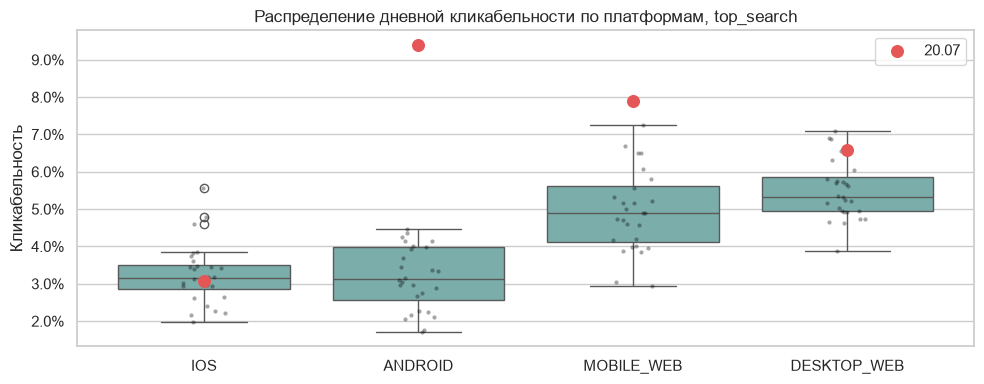

In [151]:
display(fig_dist)
display(fig_platform)
fig_effect.show()


**Ограничения.**
- Проверки ловят дубли, пропуски и разрыв воронки. Аккуратно записанные лишние клики, автокликеры или боты они не видят: в данных нет времени события, типа устройства и версии приложения.
- Сравнение показывает, что 20.07 отличался, но не почему. Без эксперимента нельзя утверждать, что виноват релиз, акция или изменение выдачи.

**Рекомендованное действие.**
1. Продакт-менеджер: сообщить об эффекте и уточнить, было ли 20.07 на Android что-то новое (релиз, акция, изменение выдачи).
2. Формат показа на Android не менять, пока нет объяснения. Если всплеск повторится, проверить A/B-тестом.